# Customer Segmentation — End-to-End Notebook

**Business problem:** *FreshCart*, a (fictional) online grocery store, sends the same offers to every customer. Marketing
wants to split customers into a handful of **segments** with similar shopping behaviour, so each group can get a
message that suits it (rewards for loyal shoppers, win-back offers for customers who stopped buying, and so on).

**What kind of ML is this?** There is **no target column**. Nobody has labelled customers as "loyal" or "deal seeker".
We use **unsupervised learning (clustering)**: the algorithm groups customers that look similar, and *we* then study
the groups and give them business names.

**Expected result:** a small number of segments that are (1) clearly different from each other, (2) stable when we
re-run the algorithm, and (3) easy to explain and act on. We save a pipeline (log transform + scaler + k-means) and a
`segment_profiles.json` file that the Flask API uses to place a new customer into a segment.

**How to run:** start Jupyter from the **project root** (the folder that contains `data/`, `models/` and `backend/`):

```bash
jupyter notebook notebook/Customer_Segmentation.ipynb
```

The first code cell changes into the project root automatically if you started Jupyter inside `notebook/`.

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

# Make paths work whether Jupyter was started in the project root or in notebook/
if os.path.basename(os.getcwd()) == "notebook":
    os.chdir("..")
print("Working folder:", os.getcwd())
RANDOM_STATE = 42
pd.set_option("display.width", 160)

Working folder: /home/claude/Student_Friendly_AI_ML_Course/End_to_End_Projects/ML_Projects/04_Customer_Segmentation


## 1. Load the data and look at it

We have **two tables**, like in a real shop database:

**`data/orders.csv`** — one row per order placed in 2025

| Column | Meaning | Type |
|---|---|---|
| `order_id` | Order identifier | text |
| `customer_id` | Who placed the order (links to `customers.csv`) | text |
| `order_date` | Date of the order (1 Jan – 31 Dec 2025) | date |
| `order_value` | Amount paid in rupees (₹) | number |
| `items` | Number of items in the basket | integer |
| `category` | Main grocery category of the basket | category (7 values) |
| `used_coupon` | 1 if a discount coupon was used, else 0 | 0 / 1 |
| `channel` | Where the order was placed: `app` or `web` | category |

**`data/customers.csv`** — one row per registered customer: `customer_id`, `age`, `city`, `signup_date`.

The data is synthetic (made by `data/generate_data.py` with a fixed seed). The hidden "true" shopping styles used to
generate it are **not** in the files — just like in real life.

In [2]:
orders = pd.read_csv("data/orders.csv", parse_dates=["order_date"])
customers = pd.read_csv("data/customers.csv", parse_dates=["signup_date"])
print("orders:", orders.shape, "  customers:", customers.shape)
orders.head()

orders: (30273, 8)   customers: (2540, 4)


,order_id,customer_id,order_date,order_value,items,category,used_coupon,channel
0,O111288,C02106,2025-05-19,744.59,7,Personal Care,0,web
1,O113976,C00481,2025-06-21,361.49,4,Fruits & Vegetables,1,app
2,O125597,C00396,2025-11-06,213.29,2,Fruits & Vegetables,0,app
3,O110645,C02259,2025-05-11,1255.02,11,Fruits & Vegetables,0,app
4,O120560,C00261,2025-09-08,502.92,1,Snacks & Beverages,0,app


In [3]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 30273 entries, 0 to 30272
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   order_id     30273 non-null  str           
 1   customer_id  30273 non-null  str           
 2   order_date   30273 non-null  datetime64[us]
 3   order_value  30213 non-null  float64       
 4   items        30273 non-null  int64         
 5   category     30273 non-null  str           
 6   used_coupon  30273 non-null  int64         
 7   channel      30273 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(2), str(4)
memory usage: 1.8 MB


In [4]:
print("Missing values in orders:")
print(orders.isna().sum())
print("\nMissing values in customers:")
print(customers.isna().sum())
print("\nFully duplicated order rows:", orders.duplicated().sum())
print("\nOrders with value <= 0:", (orders["order_value"] <= 0).sum())
print("\nChannel spellings:")
print(orders["channel"].value_counts())

Missing values in orders:
order_id        0
customer_id     0
order_date      0
order_value    60
items           0
category        0
used_coupon     0
channel         0
dtype: int64

Missing values in customers:
customer_id      0
age            120
city             0
signup_date      0
dtype: int64

Fully duplicated order rows: 150

Orders with value <= 0: 47

Channel spellings:
channel
app     19667
web     10206
 web       92
App        84
APP        77
Web        74
WEB        73
Name: count, dtype: int64


In [5]:
orders.describe().round(1)

,order_date,order_value,items,used_coupon
count,30273,30213.0,30273.0,30273.0
mean,2025-07-06 06:47:04.774551,1146.8,10.5,0.2
min,2025-01-01 00:00:00,-3542.7,1.0,0.0
25%,2025-04-08 00:00:00,621.1,5.0,0.0
50%,2025-07-03 00:00:00,955.6,9.0,0.0
75%,2025-10-01 00:00:00,1466.0,14.0,0.0
max,2025-12-31 00:00:00,8500.4,87.0,1.0
std,NaN,751.5,7.5,0.4


## 2. Clean the orders

| Problem found above | What we do | Why |
|---|---|---|
| Duplicated rows (same order exported twice) | drop them | otherwise a customer looks like they ordered more often than they did |
| `channel` written as `App`, `WEB`, `" web"` … | strip spaces + lower-case | these are the same two channels |
| Missing `order_value` | drop those orders | we cannot guess what was paid, and they are very few |
| `order_value` ≤ 0 | drop them | these are refunds / cancelled orders, not purchases |
| Missing `age` in customers | keep the customer | age is **not** used for clustering, only for describing segments afterwards |

Note: in clustering there is no train/test split, because there is no target to predict. We still follow the same
rule as before: **every statistic used by the model (log, scaling, cluster centres) lives inside a saved pipeline**,
so new customers are processed exactly like the customers we learned from.

In [6]:
n0 = len(orders)
orders = orders.drop_duplicates()
print(f"Dropped {n0 - len(orders)} duplicated rows")

orders["channel"] = orders["channel"].str.strip().str.lower()
print("Channels after cleaning:", orders["channel"].value_counts().to_dict())

n1 = len(orders)
orders = orders[orders["order_value"].notna() & (orders["order_value"] > 0)].copy()
print(f"Dropped {n1 - len(orders)} orders with missing, zero or negative value")
print("Orders left:", len(orders), "  customers with orders:", orders["customer_id"].nunique())

Dropped 150 duplicated rows
Channels after cleaning: {'app': 19725, 'web': 10398}
Dropped 105 orders with missing, zero or negative value
Orders left: 30018   customers with orders: 2500


## 3. Explore the orders

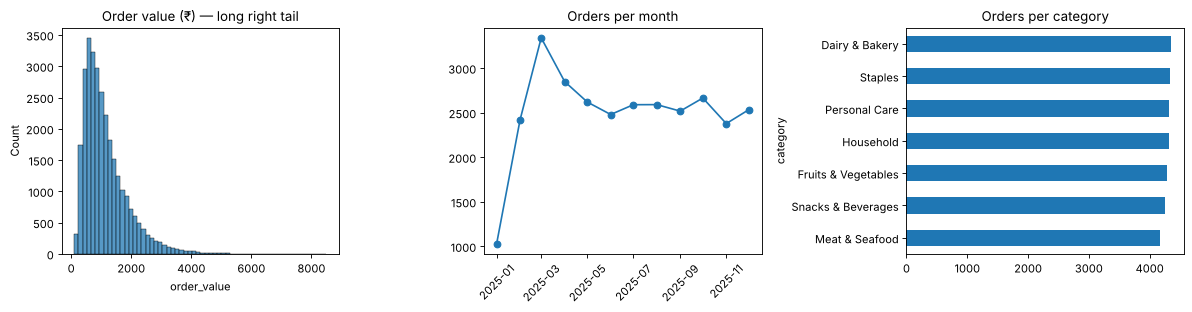

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(orders["order_value"], bins=60, ax=axes[0])
axes[0].set_title("Order value (₹) — long right tail")
monthly = orders.set_index("order_date").resample("MS")["order_id"].count()
axes[1].plot(monthly.index, monthly.values, marker="o")
axes[1].set_title("Orders per month"); axes[1].tick_params(axis="x", rotation=45)
orders["category"].value_counts().sort_values().plot.barh(ax=axes[2], title="Orders per category")
plt.tight_layout()

In [8]:
orders_per_customer = orders.groupby("customer_id").size()
print(orders_per_customer.describe().round(1))
print("\nCoupon used on", f"{orders['used_coupon'].mean():.0%}", "of orders;",
      "app share of orders:", f"{(orders['channel'] == 'app').mean():.0%}")

count    2500.0
mean       12.0
std        10.1
min         1.0
25%         4.0
50%         9.0
75%        17.2
max        60.0
dtype: float64

Coupon used on 25% of orders; app share of orders: 65%


**What to notice:** most orders are a few hundred to a couple of thousand rupees, but a few are much larger (a long
right tail). The number of orders per customer is also very uneven: the median customer ordered far fewer times than
the most active ones. Monthly orders rise during the first quarter (many customers place their first order of the
year in January–February) and then stay roughly flat. A flat total can hide a lot: some customers stop shopping while
others shop more. The total cannot tell us *who* is who — segmentation can.

## 4. Feature engineering: from orders to one row per customer (RFM+)

Clustering needs **one row per customer**. We summarise each customer's orders into seven numbers. The first three are
the classic marketing **RFM** features:

| Feature | How it is computed | Business meaning |
|---|---|---|
| `recency_days` | days from the customer's last order to the reference date (1 Jan 2026) | small = shopped recently |
| `frequency` | number of orders in 2025 | how often they shop |
| `monetary` | total ₹ spent in 2025 | how valuable they are |
| `avg_basket` | `monetary / frequency` | size of a typical order |
| `coupon_rate` | share of orders with a coupon (0–1) | price sensitivity |
| `app_share` | share of orders placed in the app (0–1) | preferred channel |
| `category_variety` | number of different categories bought (1–7) | how much of their grocery shopping they do with us |

The **reference date** is the day after the last order in the data, as if we were running this analysis on
1 January 2026.

In [9]:
reference_date = orders["order_date"].max() + pd.Timedelta(days=1)
print("Reference date:", reference_date.date())

feats = orders.groupby("customer_id").agg(
    last_order=("order_date", "max"),
    frequency=("order_id", "nunique"),
    monetary=("order_value", "sum"),
    coupon_rate=("used_coupon", "mean"),
    app_share=("channel", lambda s: (s == "app").mean()),
    category_variety=("category", "nunique"),
)
feats["recency_days"] = (reference_date - feats["last_order"]).dt.days
feats["avg_basket"] = feats["monetary"] / feats["frequency"]

FEATURES = ["recency_days", "frequency", "monetary", "avg_basket", "coupon_rate", "app_share", "category_variety"]
feats = feats[FEATURES].round({"monetary": 2, "avg_basket": 2, "coupon_rate": 3, "app_share": 3})
print("Customer feature table:", feats.shape)
feats.head()

Reference date: 2026-01-01
Customer feature table: (2500, 7)


,recency_days,frequency,monetary,avg_basket,coupon_rate,app_share,category_variety
customer_id,,,,,,,
C00001,16,4,4080.18,1020.04,0.250,0.000,2
C00002,31,8,4621.80,577.72,0.875,0.875,3
C00003,322,1,478.03,478.03,0.000,1.000,1
C00004,98,6,4127.90,687.98,0.167,0.000,3
C00005,1,27,40548.40,1501.79,0.148,1.000,6


In [10]:
never_ordered = set(customers["customer_id"]) - set(feats.index)
print(f"{len(never_ordered)} registered customers never placed an order in 2025.")
print("They have no behaviour to cluster, so they are left out and handled separately "
      "(e.g. a 'welcome' campaign).")
feats.describe().round(2)

40 registered customers never placed an order in 2025.
They have no behaviour to cluster, so they are left out and handled separately (e.g. a 'welcome' campaign).


,recency_days,frequency,monetary,avg_basket,coupon_rate,app_share,category_variety
count,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00
mean,86.98,12.01,13807.93,1004.49,0.29,0.53,3.43
std,106.46,10.09,18732.94,503.02,0.30,0.30,1.74
min,1.00,1.00,297.46,218.65,0.00,0.00,1.00
25%,11.00,4.00,3429.40,645.42,0.00,0.33,2.00
50%,31.00,9.00,6459.26,896.30,0.20,0.59,3.00
75%,130.00,17.25,15184.61,1241.24,0.50,0.75,5.00
max,364.00,60.00,138400.71,4134.72,1.00,1.00,7.00


## 5. Handle skew and scale the features

K-means groups points by **distance**. Two problems would make the distances misleading:

1. **Skew.** `monetary`, `frequency`, `avg_basket` and `recency_days` have long right tails. A few very large
   values would dominate the distances. Taking `log1p(x) = log(1 + x)` pulls the tail in.
2. **Different units.** `monetary` is in tens of thousands of rupees while `coupon_rate` is between 0 and 1. Without
   scaling, `monetary` alone would decide the clusters. `StandardScaler` puts every feature on the same scale
   (mean 0, standard deviation 1).

Skewness before log (0 = symmetric):
recency_days        1.15
frequency           1.23
monetary            2.68
avg_basket          1.39
coupon_rate         0.83
app_share          -0.41
category_variety    0.53
dtype: float64

Skewness after log1p:
recency_days   -0.04
frequency      -0.13
monetary        0.19
avg_basket      0.04
dtype: float64


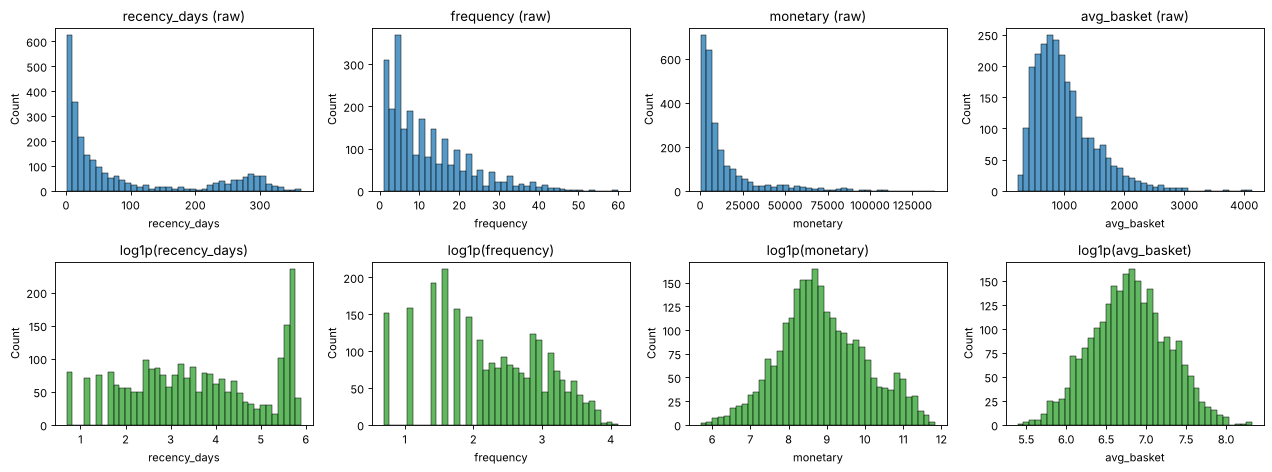

In [11]:
LOG_FEATURES = ["recency_days", "frequency", "monetary", "avg_basket"]
OTHER_FEATURES = ["coupon_rate", "app_share", "category_variety"]

print("Skewness before log (0 = symmetric):")
print(feats[FEATURES].skew().round(2))
print("\nSkewness after log1p:")
print(np.log1p(feats[LOG_FEATURES]).skew().round(2))

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for i, col in enumerate(LOG_FEATURES):
    sns.histplot(feats[col], bins=40, ax=axes[0, i]); axes[0, i].set_title(f"{col} (raw)")
    sns.histplot(np.log1p(feats[col]), bins=40, ax=axes[1, i], color="tab:green")
    axes[1, i].set_title(f"log1p({col})")
plt.tight_layout()

We put the log step and the scaler in **one preprocessing pipeline**. Later the k-means model is added as the last
step, so the API can send raw feature values and receive a segment number.

In [12]:
def make_preprocess():
    log_then_keep = ColumnTransformer([
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"), LOG_FEATURES),
        ("keep", "passthrough", OTHER_FEATURES),
    ])
    return Pipeline([("log", log_then_keep), ("scale", StandardScaler())])

preprocess = make_preprocess()
X = preprocess.fit_transform(feats[FEATURES])
print("Scaled matrix:", X.shape)
print("Means  :", X.mean(axis=0).round(2))
print("Std devs:", X.std(axis=0).round(2))

Scaled matrix: (2500, 7)
Means  : [ 0.  0.  0. -0.  0. -0. -0.]
Std devs: [1. 1. 1. 1. 1. 1. 1.]


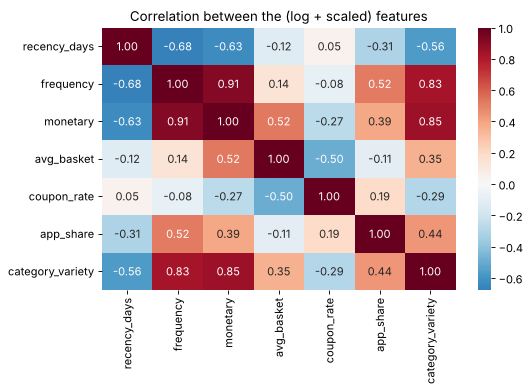

In [13]:
plt.figure(figsize=(7, 5))
sns.heatmap(pd.DataFrame(X, columns=LOG_FEATURES + OTHER_FEATURES).corr(), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0)
plt.title("Correlation between the (log + scaled) features")
plt.tight_layout()

**Reading the heatmap:** frequency, monetary and category variety move together (people who shop often spend more and
buy more kinds of things), and recency is negatively related to them (frequent shoppers ordered recently). Correlated
features are fine for k-means, but remember that this "activity" idea is counted several times in the distance.

## 6. How many segments? Elbow and silhouette

K-means needs the number of clusters **k** in advance. We try k = 2 … 9 and look at two scores:

- **Inertia** (within-cluster sum of squares): how tight the clusters are. It always falls as k grows; we look for the
  **elbow** where adding clusters stops helping much.
- **Silhouette score** (−1 to 1): how much closer each customer is to its own cluster than to the next one.
  Higher = better separated.

`n_init=10` runs k-means from 10 different random starts and keeps the best, which avoids bad local solutions.

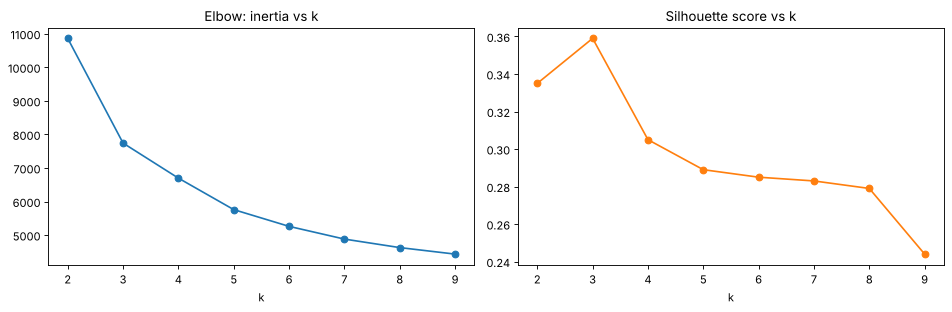

,inertia,silhouette,smallest_cluster_%
k,,,
2,10862.687,0.335,35.68
3,7741.400,0.359,24.76
4,6696.855,0.305,12.60
5,5758.457,0.289,12.60
6,5259.037,0.285,9.08
7,4879.985,0.283,7.04
8,4626.516,0.279,5.68
9,4432.347,0.244,4.92


In [14]:
k_rows = []
for k in range(2, 10):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    k_rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X, km.labels_),
                   "smallest_cluster_%": 100 * np.bincount(km.labels_).min() / len(X)})
k_scores = pd.DataFrame(k_rows).set_index("k").round(3)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_scores.index, k_scores["inertia"], marker="o"); axes[0].set_title("Elbow: inertia vs k")
axes[0].set_xlabel("k")
axes[1].plot(k_scores.index, k_scores["silhouette"], marker="o", color="tab:orange")
axes[1].set_title("Silhouette score vs k"); axes[1].set_xlabel("k")
plt.tight_layout()
k_scores

**What the numbers say:** the silhouette score is highest at **k = 3**, and the elbow bends around k = 3–5. Scores
alone would pick 3. Let us look at what 3 segments and 5 segments actually *mean* before deciding.

In [15]:
def profile(labels):
    table = feats.assign(segment=labels).groupby("segment")[FEATURES].median()
    table["customers"] = pd.Series(labels).value_counts().sort_index().values
    return table.round(2)

for k in (3, 5):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    print(f"\n--- k = {k}: median feature values per segment ---")
    print(profile(km.labels_).to_string())


--- k = 3: median feature values per segment ---
         recency_days  frequency  monetary  avg_basket  coupon_rate  app_share  category_variety  customers
segment                                                                                                    
0                11.0       21.0  21293.42     1109.64         0.10       0.68               5.0        877
1                30.0       10.0   5042.28      529.78         0.69       0.71               3.0        619
2               164.0        4.0   3669.28      978.13         0.12       0.25               2.0       1004

--- k = 5: median feature values per segment ---
         recency_days  frequency  monetary  avg_basket  coupon_rate  app_share  category_variety  customers
segment                                                                                                    
0                23.0       11.0   5482.95      514.33         0.70       0.71               3.0        505
1                13.0       17.0  15

### Choosing k with business reasoning

- With **k = 3**, one large group mixes two very different kinds of inactive customers: people who used to shop and
  **stopped months ago** (very high recency) and people who shop **rarely but still recently, mostly on the website**.
  Marketing would treat these two very differently (win-back offer vs. app-install nudge), so 3 is too coarse.
  It also mixes the very best customers with ordinary regulars.
- With **k = 5**, each segment has a clear, different story (see the profile table in section 8), every segment is
  large enough to target, and the silhouette is only somewhat lower than for k = 3.
- More than 5 segments would be hard for a marketing team to run campaigns for, and the extra splits get small.

**Decision: k = 5.** This is a normal trade-off: the "best" score is not always the most useful answer.

In [16]:
K = 5
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X)
labels = kmeans.labels_
print("Customers per segment:", np.bincount(labels))
print("Silhouette for k = 5:", round(silhouette_score(X, labels), 3))

Customers per segment: [505 614 440 315 626]
Silhouette for k = 5: 0.289


## 7. Compare with other clustering methods (briefly)

**Hierarchical (agglomerative) clustering** builds a tree by repeatedly merging the two closest groups. The
dendrogram below (drawn on a random sample of 300 customers so it stays readable) shows how groups merge; cutting the
tree into 5 branches gives 5 clusters. We compare its labels with k-means using the **Adjusted Rand Index (ARI)**:
1 = identical grouping, 0 = no better than random.

Agglomerative (k=5) silhouette: 0.255
Agreement with k-means (ARI):   0.727


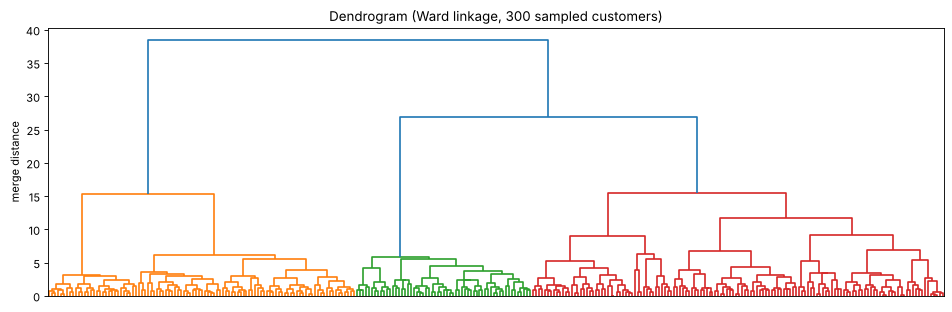

In [17]:
sample = np.random.default_rng(RANDOM_STATE).choice(len(X), 300, replace=False)
plt.figure(figsize=(12, 4))
dendrogram(linkage(X[sample], method="ward"), no_labels=True, color_threshold=None)
plt.title("Dendrogram (Ward linkage, 300 sampled customers)"); plt.ylabel("merge distance")
plt.tight_layout()

agglo = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X)
print("Agglomerative (k=5) silhouette:", round(silhouette_score(X, agglo), 3))
print("Agreement with k-means (ARI):  ", round(adjusted_rand_score(labels, agglo), 3))

**DBSCAN** finds dense regions and marks isolated points as noise (label −1). It does not need k, but it needs a
distance `eps`:

In [18]:
for eps in (0.8, 1.0, 1.2):
    db = DBSCAN(eps=eps, min_samples=10).fit_predict(X)
    sizes = pd.Series(db).value_counts().to_dict()
    print(f"eps={eps}: clusters (label: size) -> {sizes}")

eps=0.8: clusters (label: size) -> {0: 1516, -1: 550, 2: 342, 1: 34, 3: 21, 5: 19, 4: 18}
eps=1.0: clusters (label: size) -> {0: 2358, -1: 109, 2: 22, 1: 11}
eps=1.2: clusters (label: size) -> {0: 2429, -1: 31, 2: 24, 1: 16}


**Conclusion of the comparison:**
- Hierarchical clustering finds a broadly similar structure to k-means (ARI clearly above 0), which is reassuring.
- DBSCAN is **not** a good fit here: customers form one large, continuous cloud rather than separate dense islands, so
  with a small `eps` DBSCAN labels about a fifth of all customers as noise, and with a larger `eps` almost everyone
  falls into one giant cluster plus a few tiny ones. Neither is useful for marketing.
- **K-means** gives balanced, interpretable groups and can assign a *new* customer to the nearest centre, which is
  exactly what our API needs (agglomerative clustering and DBSCAN have no `predict` for new points).

## 8. Profile the segments and give them names

Cluster numbers (0, 1, 2 …) mean nothing to a marketer. We look at the **median** of each feature per segment
(medians are robust to the long tails) and compare it with the median of all customers.

In [19]:
profiles = profile(labels)
overall = feats[FEATURES].median()
print("All customers (median):")
print(overall.round(2).to_string())
profiles

All customers (median):
recency_days          31.00
frequency              9.00
monetary            6459.26
avg_basket           896.30
coupon_rate            0.20
app_share              0.59
category_variety       3.00


,recency_days,frequency,monetary,avg_basket,coupon_rate,app_share,category_variety,customers
segment,,,,,,,,
0,23.0,11.0,5482.95,514.33,0.70,0.71,3.0,505
1,13.0,17.0,15138.26,901.93,0.11,0.61,5.0,614
2,275.0,4.0,2626.26,746.95,0.33,0.56,2.0,440
3,9.0,30.0,51253.73,1702.94,0.09,0.82,7.0,315
4,83.0,4.0,4189.16,1122.58,0.00,0.00,2.0,626


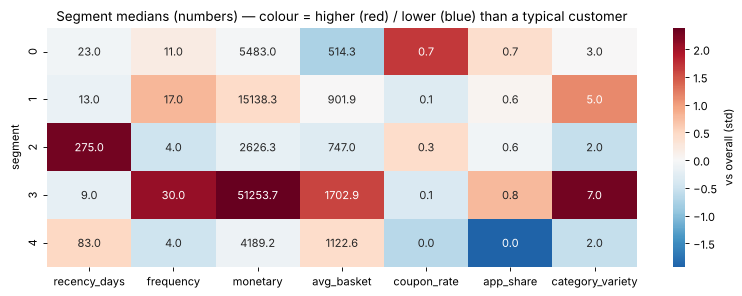

In [20]:
# Heatmap: how far each segment's median is from the overall median, in standard deviations
relative = (profiles[FEATURES] - overall) / feats[FEATURES].std()
plt.figure(figsize=(10, 3.8))
sns.heatmap(relative, annot=profiles[FEATURES].round(1), fmt="", cmap="RdBu_r", center=0, cbar_kws={"label": "vs overall (std)"})
plt.title("Segment medians (numbers) — colour = higher (red) / lower (blue) than a typical customer")
plt.ylabel("segment"); plt.tight_layout()

### Naming rules

Instead of typing names next to cluster numbers by hand (the numbers can change if the data changes), we name the
segments with simple, readable **rules on the profile table**, applied one after another:

1. highest median **monetary** → **Loyal big spenders**
2. highest median **coupon_rate** (of the rest) → **Deal seekers**
3. highest median **recency_days** (of the rest) → **Lapsed customers**
4. lowest median **app_share** (of the rest) → **Occasional web shoppers**
5. the remaining segment → **Regular shoppers**

Each name comes with a plain-English description and a suggested marketing action.

In [21]:
SEGMENT_TEXT = {
    "Loyal big spenders": (
        "Shop very often, recently, with large baskets across almost every category. Rarely need coupons.",
        "Reward and retain: VIP/loyalty tier, early access to new products, free delivery. Avoid unnecessary discounts."),
    "Deal seekers": (
        "Order fairly regularly but with small baskets, and use a coupon on most orders. Mostly in the app.",
        "Targeted coupons on bigger baskets (e.g. 'save ₹100 on orders above ₹800') and bundle offers to raise basket size."),
    "Lapsed customers": (
        "Ordered a few times but have not come back for many months. At risk of being lost.",
        "Win-back campaign: 'we miss you' message with a time-limited offer; ask for feedback on why they stopped."),
    "Occasional web shoppers": (
        "Order rarely, almost always on the website, from few categories, with medium-to-large baskets and few coupons.",
        "Push the app (first app-order discount) and remind them about categories they have not tried yet."),
    "Regular shoppers": (
        "Steady, recent customers who order around every few weeks across several categories.",
        "Grow the relationship: personalised recommendations, subscriptions for staples, cross-sell new categories."),
}

def name_segments(prof):
    names, left = {}, list(prof.index)
    def pick(column, highest, name):
        seg = prof.loc[left, column].idxmax() if highest else prof.loc[left, column].idxmin()
        names[seg] = name
        left.remove(seg)
    pick("monetary", True, "Loyal big spenders")
    pick("coupon_rate", True, "Deal seekers")
    pick("recency_days", True, "Lapsed customers")
    pick("app_share", False, "Occasional web shoppers")
    names[left[0]] = "Regular shoppers"
    return names

segment_names = name_segments(profiles)
named = profiles.assign(name=pd.Series(segment_names))
named[["name", "customers"] + FEATURES]

,name,customers,recency_days,frequency,monetary,avg_basket,coupon_rate,app_share,category_variety
segment,,,,,,,,,
0,Deal seekers,505,23.0,11.0,5482.95,514.33,0.70,0.71,3.0
1,Regular shoppers,614,13.0,17.0,15138.26,901.93,0.11,0.61,5.0
2,Lapsed customers,440,275.0,4.0,2626.26,746.95,0.33,0.56,2.0
3,Loyal big spenders,315,9.0,30.0,51253.73,1702.94,0.09,0.82,7.0
4,Occasional web shoppers,626,83.0,4.0,4189.16,1122.58,0.00,0.00,2.0


### Do the names match the numbers?

Read the table above row by row and check each description:

- **Loyal big spenders** — the smallest segment, with by far the highest frequency and total spend, the most recent
  orders, the largest baskets, the widest category variety, few coupons and mostly app orders.
- **Deal seekers** — coupon on most orders (median coupon rate around 0.7, versus about 0.2 overall) and the smallest
  baskets; they still shop fairly regularly.
- **Lapsed customers** — median last order many months before the reference date, and only a few orders in total.
- **Occasional web shoppers** — few orders and an app share near 0 (they use the website), with medium-to-large
  baskets and almost no coupons. Their recency is in between: not lost, but not frequent.
- **Regular shoppers** — recent, above-average frequency and spend, several categories, normal basket size.

These descriptions are what the API returns, so they must stay true to this table.

In [22]:
# Extra description with columns that were NOT used for clustering: age and city (from customers.csv)
seg_series = pd.Series(labels, index=feats.index, name="segment").map(segment_names)
cust = customers.set_index("customer_id").join(seg_series, how="inner")
cust["tenure_years"] = (reference_date - cust["signup_date"]).dt.days / 365.25
print(cust.groupby("segment").agg(customers=("city", "size"), median_age=("age", "median"),
                                  median_tenure_years=("tenure_years", "median"),
                                  top_city=("city", lambda s: s.mode()[0])).round(1).to_string())

                         customers  median_age  median_tenure_years   top_city
segment                                                                       
Deal seekers                   505        37.0                  2.6  Bengaluru
Lapsed customers               440        37.0                  2.6  Bengaluru
Loyal big spenders             315        36.5                  2.4  Bengaluru
Occasional web shoppers        626        35.0                  2.5  Bengaluru
Regular shoppers               614        36.0                  2.5  Bengaluru


Age, city and tenure look similar across segments. That is useful to know: the segments are defined by **behaviour**,
not by demographics, so marketing should not target them by age or city.

## 9. Visualise the segments with PCA

We have 7 features, but a screen has 2 dimensions. **PCA** (principal component analysis) finds the two directions that
keep as much of the spread of the data as possible. It is only used for the picture — the clustering itself used all
7 features.

Share of variance kept by the 2 components: [0.526 0.232] total 0.758


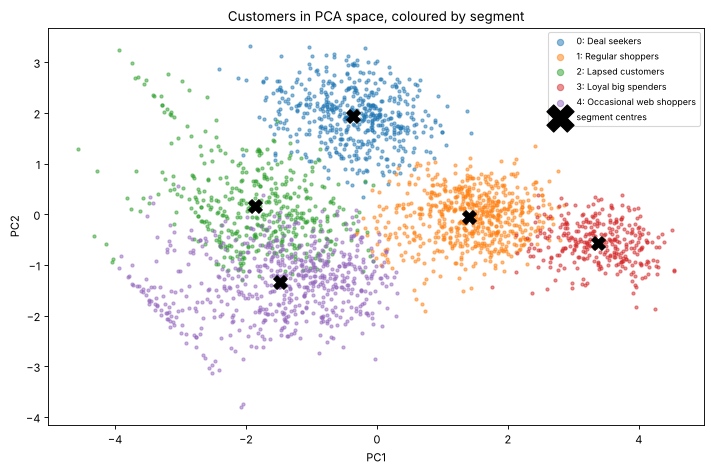

In [23]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X2 = pca.fit_transform(X)
centres2 = pca.transform(kmeans.cluster_centers_)
print("Share of variance kept by the 2 components:", pca.explained_variance_ratio_.round(3),
      "total", round(pca.explained_variance_ratio_.sum(), 3))

plt.figure(figsize=(9, 6))
for seg, name in sorted(segment_names.items()):
    m = labels == seg
    plt.scatter(X2[m, 0], X2[m, 1], s=8, alpha=0.5, label=f"{seg}: {name}")
plt.scatter(centres2[:, 0], centres2[:, 1], c="black", marker="X", s=150, label="segment centres")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend(fontsize=8, markerscale=2)
plt.title("Customers in PCA space, coloured by segment")
plt.tight_layout()

In [24]:
# What do the two axes mean? Look at the PCA loadings (weight of each feature)
pd.DataFrame(pca.components_.T, index=LOG_FEATURES + OTHER_FEATURES, columns=["PC1", "PC2"]).round(2)

,PC1,PC2
recency_days,-0.38,-0.16
frequency,0.48,0.18
monetary,0.50,-0.08
avg_basket,0.22,-0.59
coupon_rate,-0.14,0.62
app_share,0.27,0.45
category_variety,0.48,-0.02


**Reading the plot:** PC1 is mainly an "activity" axis (frequency, spend, variety up; recency down), so loyal big
spenders sit at one end and lapsed customers at the other. PC2 is driven by coupon use and app share (positive) versus
average basket size (negative), which separates deal seekers (coupons, app, small baskets) from occasional web shoppers
(website, larger baskets, no coupons). Segments overlap at their borders: customers change
gradually, so some people are naturally "between" two segments.

## 10. Are the segments stable?

A segmentation is only useful if it does not change every time we run it. Two checks, both measured with ARI against
our chosen labels:

1. **Different random seeds:** run k-means again with other `random_state` values.
2. **Bootstrap:** fit k-means on a random resample of customers (drawn with replacement), then assign *all* customers
   with that model. If the segments are real structure, the assignments should hardly change.

{'seed_ari_mean': 0.997, 'seed_ari_min': 0.996, 'bootstrap_ari_mean': 0.972, 'bootstrap_ari_min': 0.94}


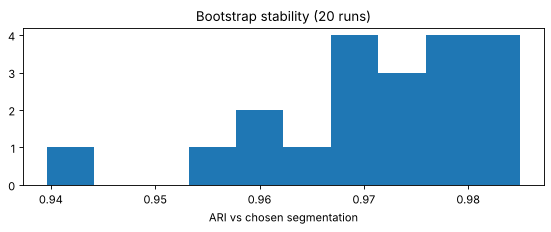

In [25]:
seed_ari = [adjusted_rand_score(labels, KMeans(K, n_init=10, random_state=s).fit_predict(X)) for s in range(1, 11)]
rng = np.random.default_rng(RANDOM_STATE)
boot_ari = []
for b in range(20):
    idx = rng.choice(len(X), len(X), replace=True)
    km_b = KMeans(K, n_init=10, random_state=b).fit(X[idx])
    boot_ari.append(adjusted_rand_score(labels, km_b.predict(X)))

stability = {"seed_ari_mean": float(np.mean(seed_ari)), "seed_ari_min": float(np.min(seed_ari)),
             "bootstrap_ari_mean": float(np.mean(boot_ari)), "bootstrap_ari_min": float(np.min(boot_ari))}
print({k: round(v, 3) for k, v in stability.items()})

plt.figure(figsize=(7, 3))
plt.hist(boot_ari, bins=10); plt.xlabel("ARI vs chosen segmentation"); plt.title("Bootstrap stability (20 runs)")
plt.tight_layout()

**Result:** the ARI values are close to 1 both for different seeds and for bootstrap resamples, so the 5 segments are
stable for this data. Try the same check yourself with other values of k (exercise): agreement that drops or varies a
lot is a sign that the clusters are less trustworthy.

## 11. Build the final pipeline and assign new customers

The final pipeline = log transform → scaler → k-means. We refit it on all customers with the same settings and check
that it reproduces exactly the labels we profiled.

In [26]:
segmenter = Pipeline([("preprocess", make_preprocess()),
                      ("kmeans", KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE))])
segmenter.fit(feats[FEATURES])
assert (segmenter.predict(feats[FEATURES]) == labels).all()
print("Pipeline reproduces the profiled segments for all", len(feats), "customers.")

Pipeline reproduces the profiled segments for all 2500 customers.


In [27]:
new_customers = pd.DataFrame([
    # recent, very frequent, big baskets, everything in the app
    {"recency_days": 4, "frequency": 35, "monetary": 60000, "avg_basket": 1714.29, "coupon_rate": 0.05,
     "app_share": 0.9, "category_variety": 7},
    # coupon on almost every small order
    {"recency_days": 15, "frequency": 12, "monetary": 5400, "avg_basket": 450.0, "coupon_rate": 0.9,
     "app_share": 0.8, "category_variety": 3},
    # last order 10 months ago
    {"recency_days": 300, "frequency": 3, "monetary": 2100, "avg_basket": 700.0, "coupon_rate": 0.33,
     "app_share": 0.67, "category_variety": 2},
    # edge case: a single order, last week, on the website
    {"recency_days": 7, "frequency": 1, "monetary": 1200, "avg_basket": 1200.0, "coupon_rate": 0.0,
     "app_share": 0.0, "category_variety": 1},
])
distances = segmenter.transform(new_customers)          # distance to every segment centre
new_customers["segment"] = segmenter.predict(new_customers)
new_customers["segment_name"] = new_customers["segment"].map(segment_names)
sorted_d = np.sort(distances, axis=1)
new_customers["closest/second distance"] = (sorted_d[:, 0] / sorted_d[:, 1]).round(2)
new_customers[["recency_days", "frequency", "monetary", "coupon_rate", "app_share", "segment_name",
               "closest/second distance"]]

,recency_days,frequency,monetary,coupon_rate,app_share,segment_name,closest/second distance
0,4,35,60000,0.05,0.90,Loyal big spenders,0.25
1,15,12,5400,0.90,0.80,Deal seekers,0.25
2,300,3,2100,0.33,0.67,Lapsed customers,0.16
3,7,1,1200,0.00,0.00,Occasional web shoppers,0.62


The first three customers land in the segments their behaviour suggests, and each is much closer to its own centre
than to any other (small ratio). The last one is an **edge case**: one order gives very little information, so the
segment is a weak guess — its ratio is clearly higher than for the other three. The column *closest/second distance*
compares the distance to the nearest centre with the distance to the second-nearest: a value close to 1 means the
customer is almost as close to another segment (a **borderline** customer). The API reports this as
`"fit": "borderline"` when the ratio is above 0.8.

The API also **validates inputs** — for example `category_variety` cannot be larger than `frequency` (each order has
one main category), rates must be between 0 and 1, and `avg_basket` must equal `monetary / frequency`.

## 12. Save the pipeline and the segment profiles

- `models/segmentation_pipeline.joblib` — log + scaler + k-means (the API calls `predict` and `transform`).
- `models/segment_profiles.json` — names, descriptions, actions, sizes and median feature values per segment, the
  overall medians, valid input ranges and the quality/stability scores.

In [28]:
os.makedirs("models", exist_ok=True)
joblib.dump(segmenter, "models/segmentation_pipeline.joblib")

sizes = np.bincount(labels)
segments_json = []
for seg in range(K):
    name = segment_names[seg]
    description, action = SEGMENT_TEXT[name]
    segments_json.append({
        "id": int(seg), "name": name, "description": description, "suggested_action": action,
        "customers": int(sizes[seg]), "share": round(float(sizes[seg] / len(labels)), 3),
        "medians": {f: round(float(profiles.loc[seg, f]), 2) for f in FEATURES},
    })

segment_profiles = {
    "model": "KMeans (log1p + StandardScaler)",
    "k": K,
    "features": FEATURES,
    "integer_features": ["recency_days", "frequency", "category_variety"],
    "valid_ranges": {
        "recency_days": [0, 365],                     # the data covers one year
        "frequency": [1, int(feats["frequency"].max())],
        "monetary": [1, float(np.ceil(feats["monetary"].max()))],
        "avg_basket": [1, float(np.ceil(feats["avg_basket"].max()))],
        "coupon_rate": [0, 1],
        "app_share": [0, 1],
        "category_variety": [1, int(orders["category"].nunique())],
    },
    "overall_medians": {f: round(float(overall[f]), 2) for f in FEATURES},
    "silhouette": round(float(silhouette_score(X, labels)), 3),
    "stability": {k: round(v, 3) for k, v in stability.items()},
    "reference_date": str(reference_date.date()),
    "customers_clustered": int(len(feats)),
    "segments": segments_json,
}
with open("models/segment_profiles.json", "w") as f:
    json.dump(segment_profiles, f, indent=2, ensure_ascii=False)
print(json.dumps(segment_profiles["valid_ranges"], indent=1))
print([(s["id"], s["name"], s["customers"]) for s in segments_json])
print(sorted(os.listdir("models")))

{
 "recency_days": [
  0,
  365
 ],
 "frequency": [
  1,
  60
 ],
 "monetary": [
  1,
  138401.0
 ],
 "avg_basket": [
  1,
  4135.0
 ],
 "coupon_rate": [
  0,
  1
 ],
 "app_share": [
  0,
  1
 ],
 "category_variety": [
  1,
  7
 ]
}
[(0, 'Deal seekers', 505), (1, 'Regular shoppers', 614), (2, 'Lapsed customers', 440), (3, 'Loyal big spenders', 315), (4, 'Occasional web shoppers', 626)]
['segment_profiles.json', 'segmentation_pipeline.joblib']


In [29]:
# Reload from disk exactly as the API will, and check the assignments match
reloaded = joblib.load("models/segmentation_pipeline.joblib")
with open("models/segment_profiles.json") as f:
    reloaded_profiles = json.load(f)
assert (reloaded.predict(feats[FEATURES]) == labels).all()
assert len(reloaded_profiles["segments"]) == K
print("Reloaded pipeline gives identical segments; profiles file has", K, "segments.")

Reloaded pipeline gives identical segments; profiles file has 5 segments.


## 13. Segments change over time (a quick demonstration)

Customer behaviour moves. Let us compute the same features using **only orders up to 30 June 2025** (reference date
1 July) and assign those customers with the saved pipeline. Then we compare with their full-year segment.

In [30]:
half = orders[orders["order_date"] < "2025-07-01"]
ref_half = pd.Timestamp("2025-07-01")
h = half.groupby("customer_id").agg(last_order=("order_date", "max"), frequency=("order_id", "nunique"),
                                    monetary=("order_value", "sum"), coupon_rate=("used_coupon", "mean"),
                                    app_share=("channel", lambda s: (s == "app").mean()),
                                    category_variety=("category", "nunique"))
h["recency_days"] = (ref_half - h["last_order"]).dt.days
h["avg_basket"] = h["monetary"] / h["frequency"]
mid_year = pd.Series(reloaded.predict(h[FEATURES]), index=h.index).map(segment_names)
full_year = seg_series.loc[h.index]
moved = (mid_year != full_year).mean()
print(f"Customers active in H1: {len(h)}. Share in a different segment at mid-year vs year-end: {moved:.0%}")
pd.crosstab(mid_year.rename("segment on 1 July 2025"), full_year.rename("segment at year-end"))

Customers active in H1: 2408. Share in a different segment at mid-year vs year-end: 22%


segment at year-end,Deal seekers,Lapsed customers,Loyal big spenders,Occasional web shoppers,Regular shoppers
segment on 1 July 2025,,,,,
Deal seekers,424,25,1,0,35
Lapsed customers,71,334,0,49,66
Loyal big spenders,0,0,214,0,0
Occasional web shoppers,8,61,3,497,96
Regular shoppers,0,8,97,3,416


About one customer in five sits in a **different segment** at mid-year than at year-end (rows = mid-year,
columns = year-end). Two effects are mixed here:
- **Counting period.** Frequency and spend after six months are about half of a full year, so many mid-year
  *Regular shoppers* only become *Loyal big spenders* at year-end, and some customers who had paused at mid-year
  (*Lapsed* on 1 July) came back later.
- **Real change.** Some customers who were active in the first half stopped buying and are *Lapsed customers* by
  year-end.

The lesson: **re-compute features and re-check the segments regularly** (e.g. monthly), and normalise frequency and
spend per month if you compare periods of different length.

## 14. Limitations and possible improvements

- **Clusters are not ground truth.** K-means always returns k groups, even if the data has no real groups. The names
  are *our interpretation* of the profiles, and another analyst might choose k or names differently.
- **Segments change over time** (section 13). Retrain and re-profile regularly; track how many customers move.
- **K-means assumptions.** It prefers round, similar-sized clusters and is sensitive to scaling and outliers. We used
  log + scaling to reduce this, but borderline customers will always exist.
- **Customers with very few orders** (one order, or never ordered) give little information. Their segment is a weak
  guess; treat them as a separate "new customer" group in practice.
- **Synthetic data.** The patterns are realistic but invented. With real data, expect more noise and check for things
  like test accounts, B2B customers with huge orders, and returns.
- **Improvements to try:** Gaussian Mixture Models (soft, probabilistic membership), per-month normalised features,
  adding product-level features (organic, brand preference), and A/B testing the suggested actions to check that
  segment-based marketing really performs better.

**Next step:** start the Flask API in `backend/` (see the project README). It loads the two files saved above.